# 04 — Szövegelemzés és klasszikus modellek a BERT-címkéken / Text analysis and classical models on the BERT labels

HU: A konzulens által jónak ítélt TF-IDF-alapú szóelemzés most a **szövegből származó** címkéken fut (`label_final`),
nem a pontszám-vágáson. Utána a klasszikus modellek (NB, LogReg, SVM) megtanulják a BERT-címkéket: gyors, értelmezhető
"tanítvány" modellek, amelyek CPU-n is címkéznek.

EN: The TF-IDF word analysis (approved by the supervisor) now runs on the **text-derived** labels (`label_final`),
not on the score cut. Then the classical models (NB, LogReg, SVM) learn the BERT labels: fast, interpretable
"student" models that label on a CPU too.

In [1]:
# HU: A notebooks/ mappából futunk, ezért a szülőmappát a path-hoz adjuk (src csomag).
# EN: We run from the notebooks/ folder, so the parent folder is added to the path (src package).
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, APPROACHES, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import evaluation as ev
from src import descriptives as ds
from src import text_analysis as ta
from src import aspects as asp
from src import models_classical as mc
from src import label_validation as lv
from src import pipeline
import time

# HU: Reprodukálhatóság + egységes ábrastílus. / EN: Reproducibility + uniform figure style.
set_seed()
PATHS.ensure()
apply_plot_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

LABEL_COL = "label_final"
data = ds.prepare_star_rating(dl.read_frame(pipeline.LABELLED))
print(f"{len(data):,} reviews | label: {LABEL_COL}")
display(data[LABEL_COL].value_counts(normalize=True).round(3).to_frame("share"))

203,328 reviews | label: label_final


,share
label_final,
positive,0.788
neutral,0.155
negative,0.057


## 1. Megkülönböztető kifejezések / Distinctive terms

20:56:39 | INFO    | src.text_analysis | Vocabulary: 25517 terms (1-2-gram)
20:56:39 | INFO    | src.evaluation | Table saved: 04_distinctive_terms.csv
20:56:41 | INFO    | src.evaluation | Figure saved: 04_distinctive_terms.png


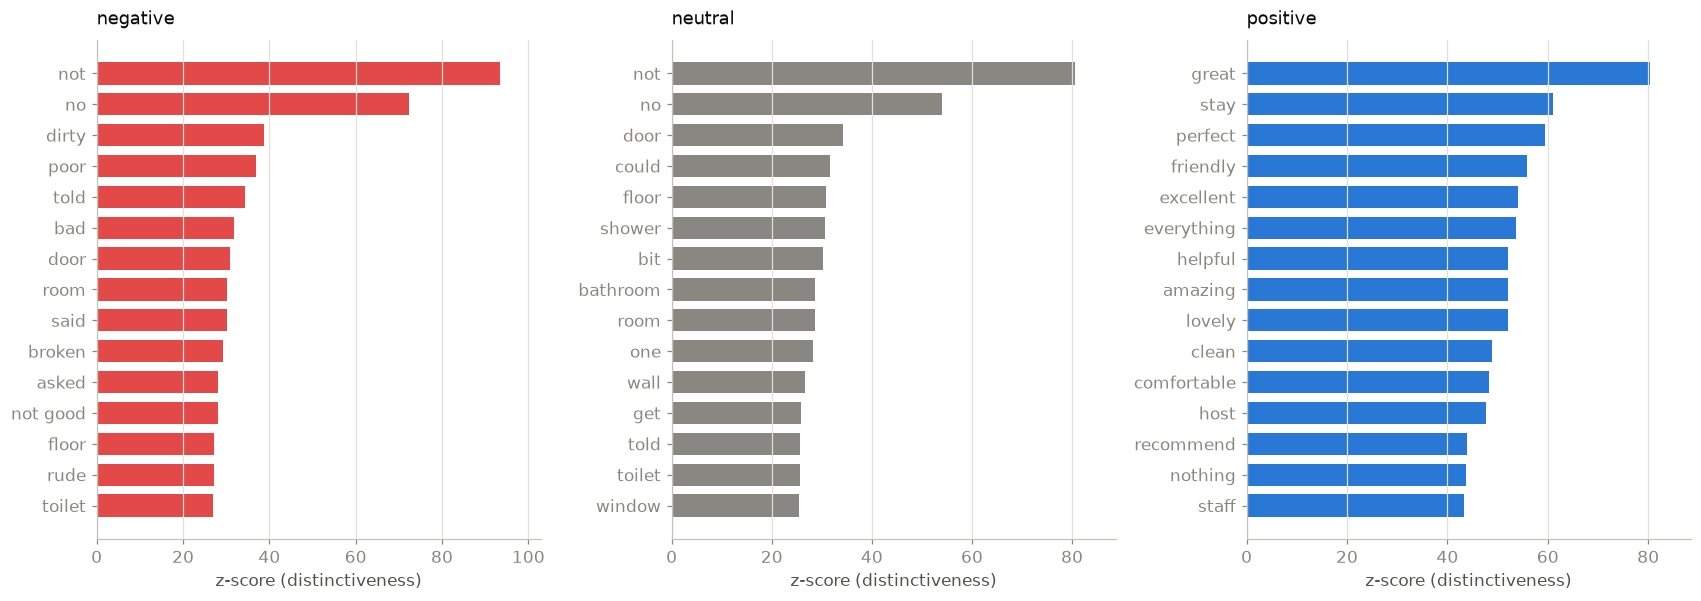

20:57:30 | INFO    | src.text_analysis | Vocabulary: 26337 terms (2-3-gram)
20:57:31 | INFO    | src.evaluation | Table saved: 04_distinctive_multiword.csv
20:57:33 | INFO    | src.evaluation | Figure saved: 04_distinctive_multiword.png


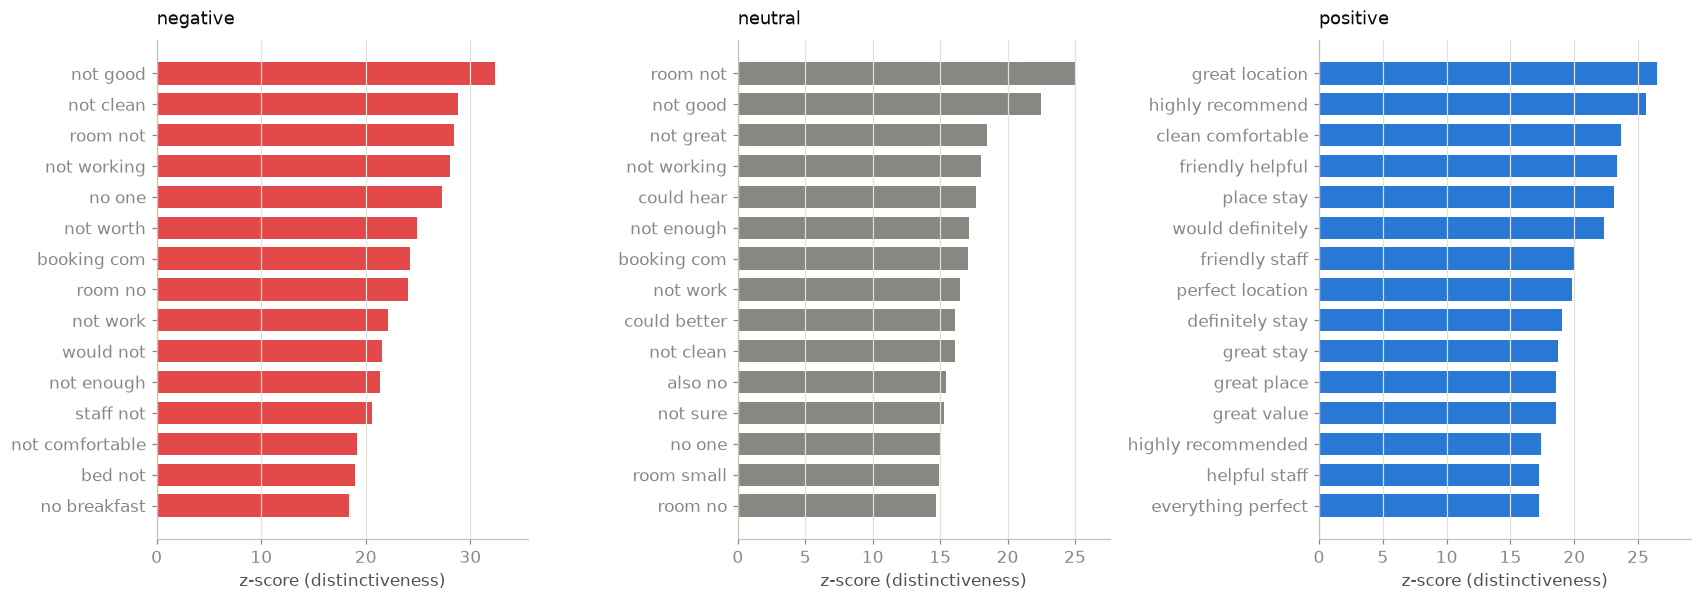

In [2]:
dist_terms = ta.distinctive_terms(data["text_clean"], data[LABEL_COL], ngram_range=(1, 2), top_n=15, min_count=30)
ev.save_table(dist_terms, "04_distinctive_terms")
ta.plot_distinctive_terms(dist_terms, save_as="04_distinctive_terms"); plt.show()

multi = ta.distinctive_terms(data["text_clean"], data[LABEL_COL], ngram_range=(2, 3), top_n=15, min_count=30)
ev.save_table(multi, "04_distinctive_multiword")
ta.plot_distinctive_terms(multi, save_as="04_distinctive_multiword"); plt.show()

20:57:53 | INFO    | src.evaluation | Table saved: 04_frequent_terms.csv


,top_n,shared_by_all_classes,mean_pairwise_jaccard
most frequent (count),15.0,10.0,0.611
most distinctive (z-score),15.0,0.0,0.101


20:57:53 | INFO    | src.evaluation | Table saved: 04_frequent_vs_distinctive_overlap.csv
20:57:57 | INFO    | src.evaluation | Figure saved: 04_frequent_vs_distinctive.png


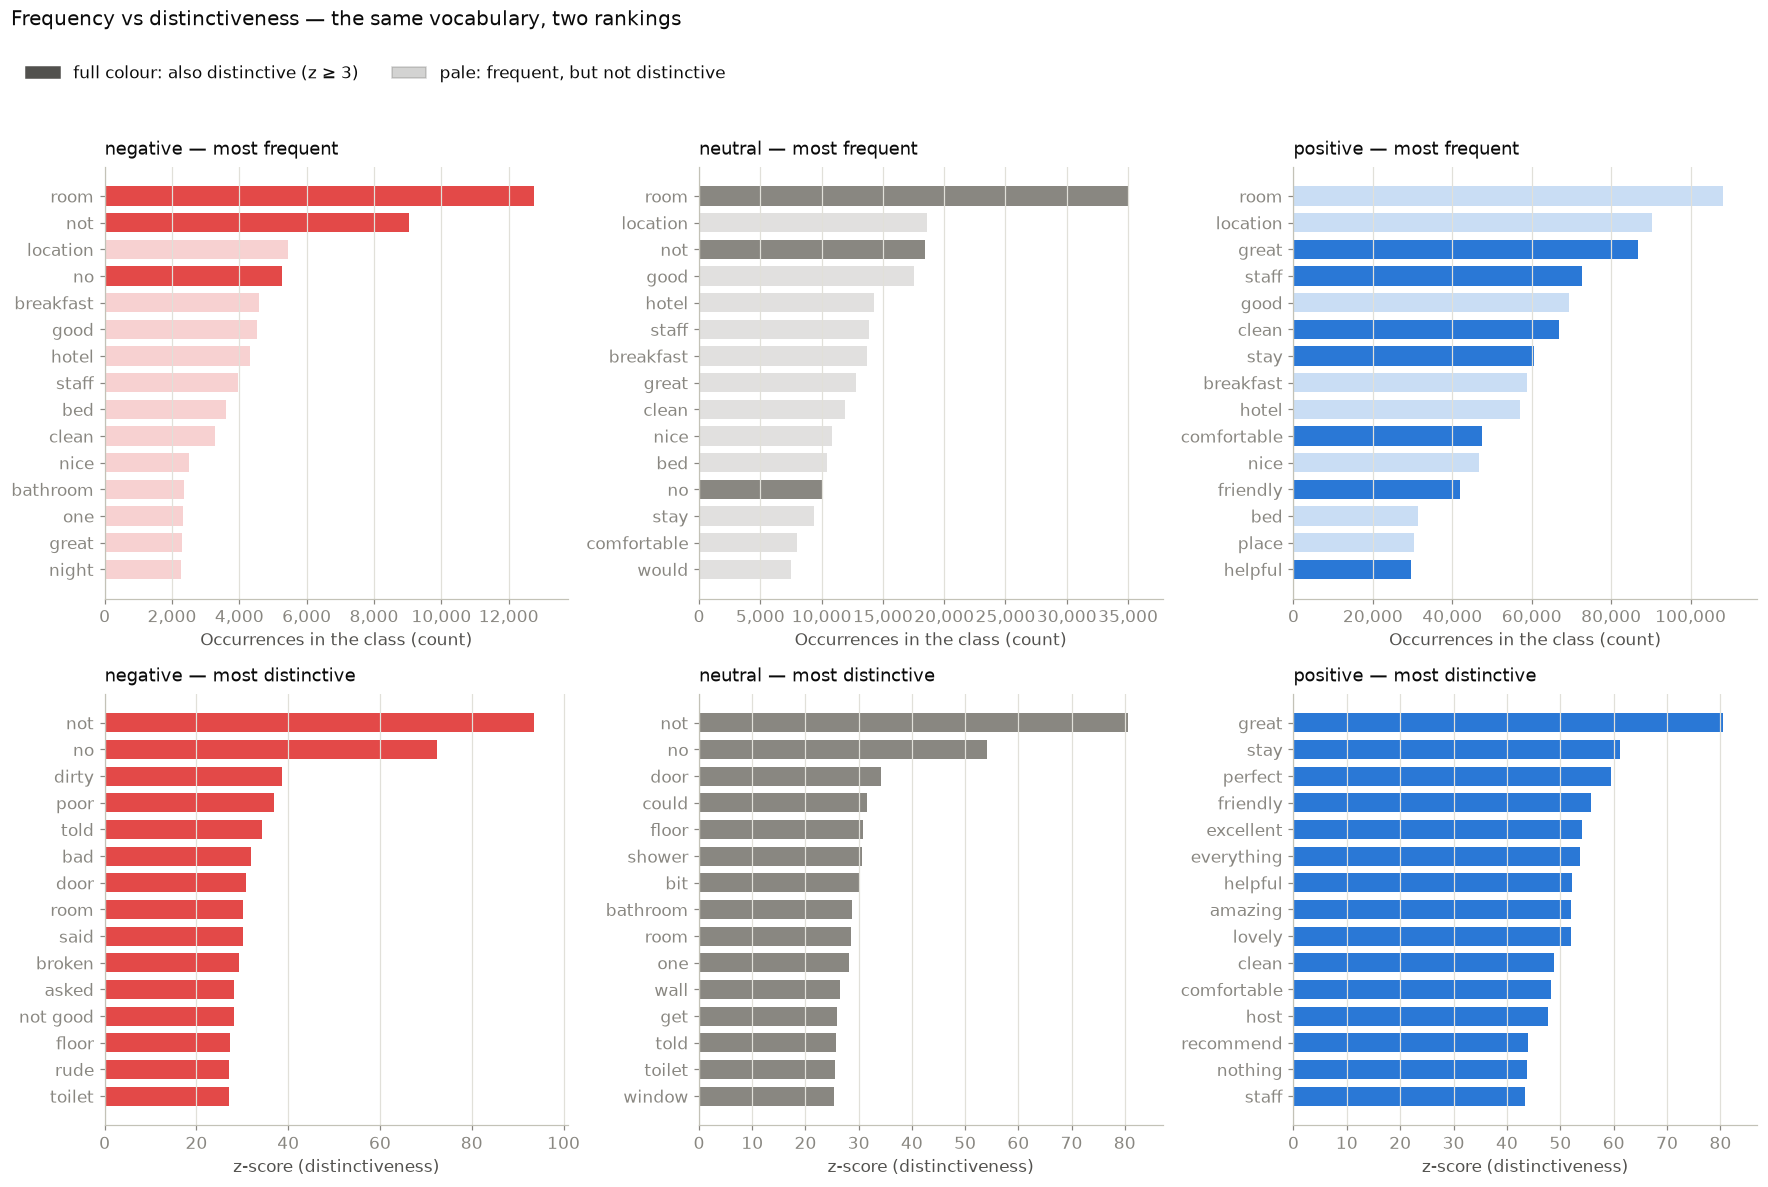

In [3]:
# HU: Gyakoriság vs. megkülönböztető erő — ugyanazon a szókincsen. A naiv gyakorisági lista
#     osztályonként szinte azonos; a z-pontszám mutatja meg, MI különbözteti meg az osztályokat.
# EN: Frequency vs distinctiveness — on the same vocabulary. The naive frequency list is nearly
#     identical across classes; the z-score shows WHAT distinguishes the classes.
freq_terms = ta.top_frequent_terms(data["text_clean"], data[LABEL_COL], ngram_range=(1, 2), top_n=15, min_count=30)
ev.save_table(freq_terms, "04_frequent_terms")
overlap = ta.top_list_overlap(freq_terms, dist_terms, top_n=15)
display(overlap); ev.save_table(overlap, "04_frequent_vs_distinctive_overlap")
ta.plot_frequency_vs_distinctive(freq_terms, dist_terms, top_n=15, save_as="04_frequent_vs_distinctive")
plt.show()

,total,negative,neutral,positive,neg_lift
bigram,,,,,
not clean,819,0.3162,0.3980,0.2857,5.5355
no one,746,0.3137,0.3941,0.2922,5.4906
not good,1537,0.2583,0.4027,0.3390,4.5212
not work,759,0.2516,0.4137,0.3347,4.4049
not working,1255,0.2486,0.3753,0.3761,4.3516
no breakfast,752,0.2141,0.3098,0.4761,3.7476
not comfortable,911,0.2042,0.3502,0.4457,3.5738
not enough,1194,0.1993,0.3693,0.4313,3.4891
not sure,730,0.1767,0.4000,0.4233,3.0932


20:58:13 | INFO    | src.evaluation | Table saved: 04_negation_bigrams.csv


,n (plain),negative share (plain),n (negated),negative share (negated),difference,lift (negated)
word,,,,,,
friendly,44970,0.0225,309,0.2945,0.2720,5.1549
clean,72172,0.0373,831,0.3057,0.2684,5.3502
helpful,32380,0.0170,238,0.2269,0.2099,3.9715
nice,46361,0.0419,315,0.2381,0.1962,4.1677
comfortable,49683,0.0310,920,0.1957,0.1646,3.4247
good,64727,0.0474,1891,0.2110,0.1636,3.6934
quiet,16419,0.0266,39,0.1795,0.1529,3.1418
recommend,13383,0.0120,251,0.1594,0.1474,2.7895
hot water,1880,0.0856,338,0.2219,0.1363,3.8841


20:59:03 | INFO    | src.evaluation | Table saved: 04_negation_effect.csv
20:59:04 | INFO    | src.evaluation | Figure saved: 04_negation_effect.png


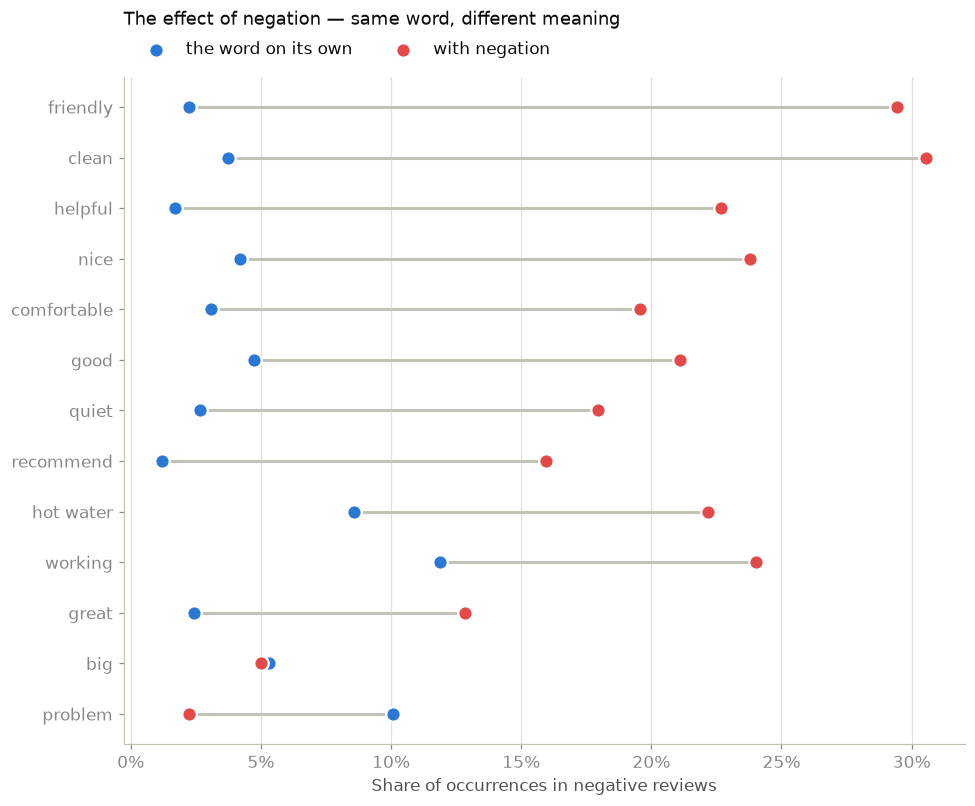

20:59:14 | INFO    | src.text_analysis | Vocabulary: 5830 terms (1-1-gram)
20:59:38 | INFO    | src.text_analysis | Vocabulary: 25517 terms (1-2-gram)
21:00:31 | INFO    | src.text_analysis | Vocabulary: 32167 terms (1-3-gram)


,top-50 mean z,multi-word share in top-50,example (negative)
n-gram level,,,
"unigram (1,1)",28.553,0.000,—
"uni+bigram (1,2)",29.543,0.133,"not good, not clean, not working"
"uni+bi+trigram (1,3)",29.712,0.140,"not good, not clean, not working"


21:00:32 | INFO    | src.evaluation | Table saved: 04_ngram_levels.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/04_ngram_levels.csv')

In [4]:
neg_bi = ta.negation_bigrams(data["text_clean"], data[LABEL_COL], min_count=20)
display(neg_bi); ev.save_table(neg_bi, "04_negation_bigrams")

neg_effect = ta.compare_with_without_negation(data["text_clean"], data[LABEL_COL])
display(neg_effect); ev.save_table(neg_effect, "04_negation_effect")
ta.plot_negation_effect(neg_effect, save_as="04_negation_effect"); plt.show()

ngram_cmp = ta.ngram_level_comparison(data["text_clean"], data[LABEL_COL], min_count=30)
display(ngram_cmp); ev.save_table(ngram_cmp, "04_ngram_levels")

## 2. Leíró statisztika és kereszttáblák / Descriptive statistics and crosstabs

In [5]:
overview = ds.dataset_overview(data, label_col=LABEL_COL)
display(overview); ev.save_table(overview, "04_dataset_overview_labelled")

crosstabs = ds.run_all_crosstabs(data, min_count=100, label_col=LABEL_COL)
for col, tab in crosstabs.items():
    print(f"=== {col} ==="); display(tab)

,Value
Metric,
Number of reviews,"203,328"
Unique properties,"5,000"
Number of countries,120
Accommodation types,24
Mean guest score,8.87
Median guest score,9.00
Guest score std,1.16
Mean review length (words),49.2
Median review length (words),37


21:00:32 | INFO    | src.evaluation | Table saved: 04_dataset_overview_labelled.csv
21:00:32 | INFO    | src.evaluation | Table saved: 04_crosstab_accommodation_country.csv
21:00:33 | INFO    | src.evaluation | Figure saved: 04_crosstab_accommodation_country.png
21:00:33 | INFO    | src.evaluation | Table saved: 04_crosstab_accommodation_type.csv
21:00:34 | INFO    | src.evaluation | Figure saved: 04_crosstab_accommodation_type.png
21:00:34 | INFO    | src.evaluation | Table saved: 04_crosstab_guest_type.csv
21:00:35 | INFO    | src.evaluation | Figure saved: 04_crosstab_guest_type.png
21:00:35 | INFO    | src.evaluation | Table saved: 04_crosstab_accommodation_star_rating.csv
21:00:35 | INFO    | src.evaluation | Figure saved: 04_crosstab_accommodation_star_rating.png


=== accommodation_country ===


,n,share,negative,neutral,positive,neg_lift,pos_lift,mean_guest_score,mean_text_score
accommodation_country,,,,,,,,,
United States of America,23651,0.1163,0.0958,0.2046,0.6996,1.6763,0.8877,8.6525,7.7009
Australia,10742,0.0528,0.0644,0.1556,0.7800,1.1276,0.9898,8.6779,8.2135
New Zealand,4049,0.0199,0.0531,0.1487,0.7982,0.9295,1.0129,8.6942,8.3391
Spain,8492,0.0418,0.0528,0.1564,0.7909,0.9234,1.0035,8.9131,8.2379
United Kingdom,38280,0.1883,0.0513,0.1501,0.7986,0.8985,1.0134,8.8075,8.2943
Thailand,5622,0.0276,0.0507,0.1617,0.7876,0.8873,0.9994,8.8844,8.2008
France,6546,0.0322,0.0478,0.1476,0.8046,0.8370,1.0210,8.7343,8.2932
Portugal,3971,0.0195,0.0436,0.1531,0.8033,0.7626,1.0193,8.9819,8.2755
Indonesia,4015,0.0197,0.0423,0.1435,0.8142,0.7411,1.0331,8.9743,8.3083


=== accommodation_type ===


,n,share,negative,neutral,positive,neg_lift,pos_lift,mean_guest_score,mean_text_score
accommodation_type,,,,,,,,,
Resort,7574,0.0373,0.0941,0.2054,0.7004,1.6478,0.8888,8.7873,7.6951
Hotel,115437,0.5677,0.0669,0.1688,0.7643,1.1703,0.9698,8.7553,8.0856
Motel,6929,0.0341,0.0658,0.1556,0.7786,1.1520,0.9880,8.5780,8.2124
Lodge,1460,0.0072,0.0575,0.1616,0.7808,1.0071,0.9908,8.9171,8.1822
Hostel,7053,0.0347,0.0567,0.1636,0.7797,0.9927,0.9893,8.8618,8.2006
ApartHotel,8371,0.0412,0.0547,0.1658,0.7795,0.9577,0.9891,8.9139,8.1701
Apartment,17315,0.0852,0.0415,0.1327,0.8258,0.7258,1.0479,9.1670,8.4341
Inn,3952,0.0194,0.0357,0.1341,0.8302,0.6245,1.0534,8.8891,8.4286
Guest house,14205,0.0699,0.0298,0.1109,0.8592,0.5225,1.0902,9.1159,8.6496


=== guest_type ===


,n,share,negative,neutral,positive,neg_lift,pos_lift,mean_guest_score,mean_text_score
guest_type,,,,,,,,,
Family with children,55197,0.2715,0.0668,0.1669,0.7663,1.1699,0.9723,8.8412,8.1061
Solo traveller,36592,0.1800,0.0634,0.1628,0.7738,1.1093,0.9819,8.7710,8.1389
Couple,86854,0.4272,0.0504,0.1461,0.8035,0.8815,1.0196,8.9214,8.3029
Group,24685,0.1214,0.0500,0.1463,0.8037,0.8750,1.0198,8.9044,8.3209


=== accommodation_star_rating ===


,n,share,negative,neutral,positive,neg_lift,pos_lift,mean_guest_score,mean_text_score
accommodation_star_rating,,,,,,,,,
2,12013,0.0591,0.0782,0.1890,0.7328,1.3697,0.9298,8.5293,7.8882
4.5,1221,0.0060,0.0753,0.1581,0.7666,1.3189,0.9727,8.6757,8.1138
5,10384,0.0511,0.0689,0.1667,0.7644,1.2053,0.9700,9.0298,8.0880
3,53490,0.2631,0.0657,0.1681,0.7662,1.1496,0.9722,8.7174,8.0899
4,58088,0.2857,0.0630,0.1644,0.7726,1.1023,0.9804,8.8493,8.1431
3.5,1715,0.0084,0.0513,0.1394,0.8093,0.8982,1.0269,8.5248,8.4286
n/a,64997,0.3197,0.0394,0.1280,0.8326,0.6892,1.0565,9.0660,8.4740
1,1402,0.0069,0.0357,0.1213,0.8431,0.6243,1.0698,8.8738,8.5606


21:00:36 | INFO    | src.evaluation | Table saved: 04_heatmap_type_x_stars.csv
21:00:39 | INFO    | src.evaluation | Figure saved: 04_heatmap_type_x_stars.png


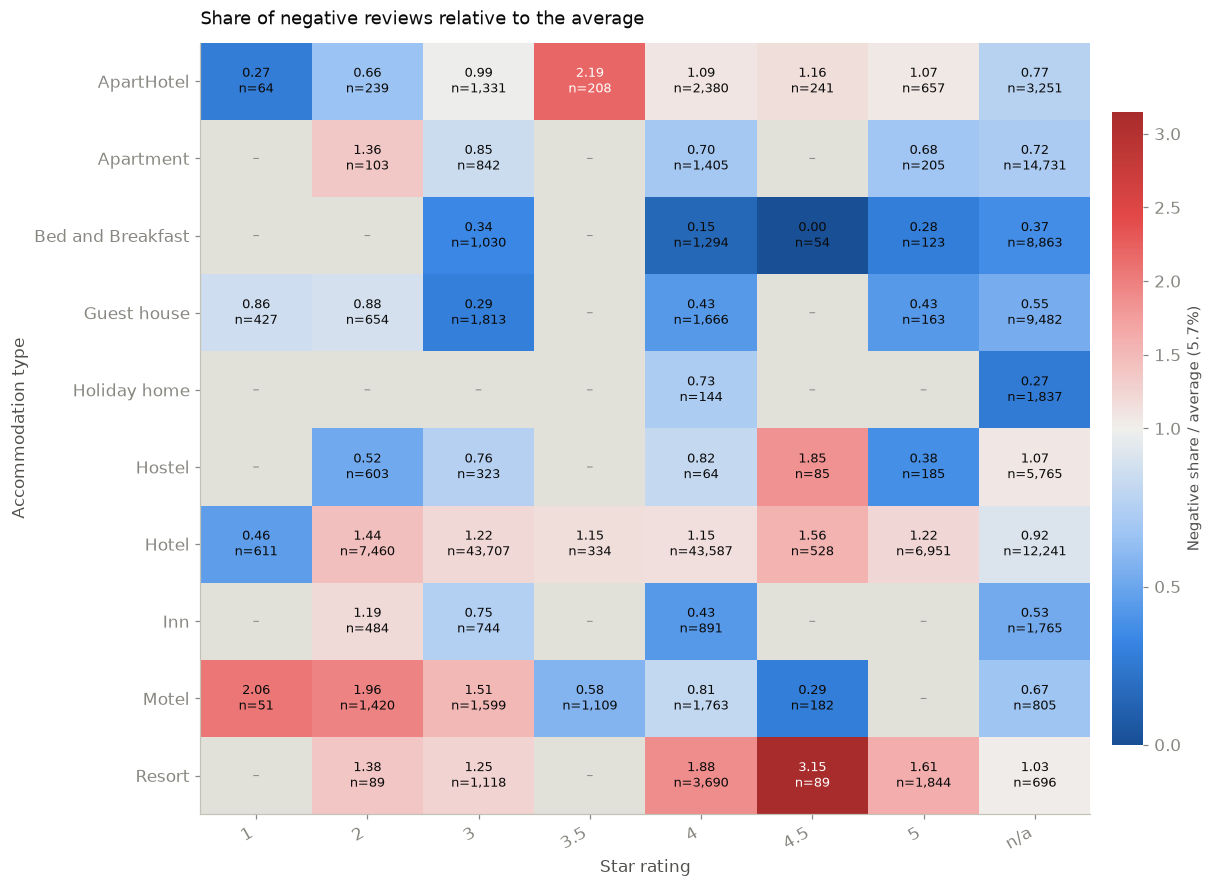

21:00:40 | INFO    | src.evaluation | Table saved: 04_heatmap_country_x_type.csv
21:00:43 | INFO    | src.evaluation | Figure saved: 04_heatmap_country_x_type.png


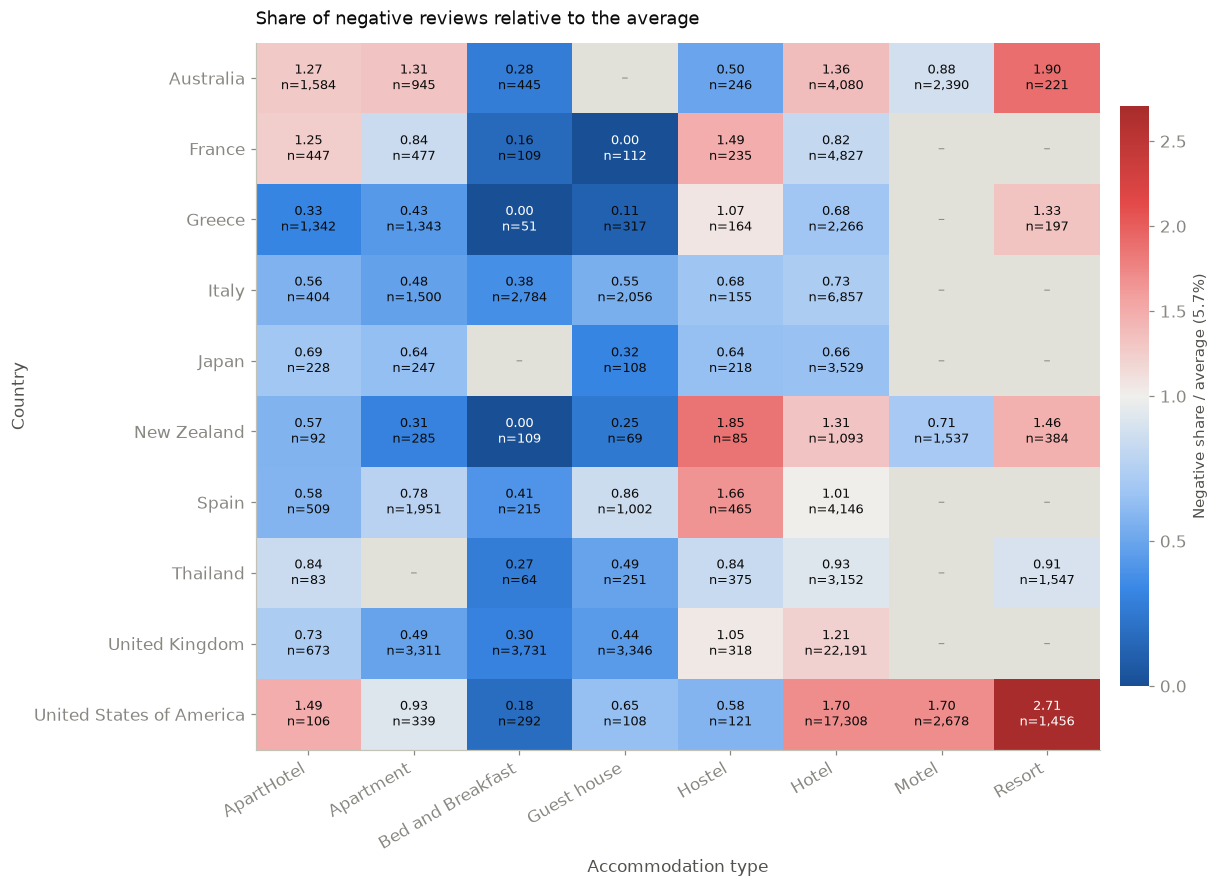

In [6]:
def heatmap(rows, cols, xlabel, ylabel, fname, min_count=50):
    """HU: Hőtérkép hibatűréssel. / EN: Heatmap with fault tolerance."""
    if not {rows, cols} <= set(data.columns):
        return print(f"Skipped — missing column: {rows}, {cols}")
    try:
        lift, counts, base = ds.negativity_heatmap(data, rows, cols, min_count=min_count, label_col=LABEL_COL)
    except ValueError as e:
        return print(f"Skipped: {e}")
    ev.save_table(lift, fname)
    ds.plot_negativity_heatmap(lift, counts, base, "Share of negative reviews relative to the average",
                               xlabel=xlabel, ylabel=ylabel, save_as=fname)
    plt.show()

heatmap("accommodation_type", "accommodation_star_rating", "Star rating", "Accommodation type", "04_heatmap_type_x_stars")
heatmap("accommodation_country", "accommodation_type", "Accommodation type", "Country", "04_heatmap_country_x_type")

## 3. Aspektusok / Aspects

HU: Két mondatszintű forrás: (1) a Booking-mező polaritása (a vendég döntése), (2) ha elérhető, a (B) modell mondatszintű
előrejelzése. A kettő összevetése maga is ellenőrzés.
EN: Two sentence-level sources: (1) the Booking field polarity (the guest's choice), (2) if available, the sentence-level
predictions of model (B). Comparing the two is a check in itself.

21:00:53 | INFO    | src.aspects | Sentences by field polarity: {'positive': 543030, 'negative': 239206}


,mentions,mention_share,negative,neutral,positive,neg_lift,pos_lift
aspect,,,,,,,
bathroom,46123,0.0590,0.5270,0.0,0.4730,1.7233,0.6814
wifi,6845,0.0088,0.5256,0.0,0.4744,1.7189,0.6833
noise,28649,0.0366,0.4086,0.0,0.5914,1.3362,0.8519
parking,15774,0.0202,0.3386,0.0,0.6614,1.1073,0.9528
facilities,59545,0.0761,0.3292,0.0,0.6708,1.0765,0.9663
room,189256,0.2419,0.3133,0.0,0.6867,1.0245,0.9892
value_for_money,31789,0.0406,0.3081,0.0,0.6919,1.0074,0.9967
pool,21503,0.0275,0.2419,0.0,0.7581,0.7911,1.0920
breakfast,97731,0.1249,0.2102,0.0,0.7898,0.6874,1.1377


21:02:09 | INFO    | src.evaluation | Table saved: 04_aspects_by_field_polarity.csv
21:02:10 | INFO    | src.evaluation | Figure saved: 04_aspects_by_field_polarity.png


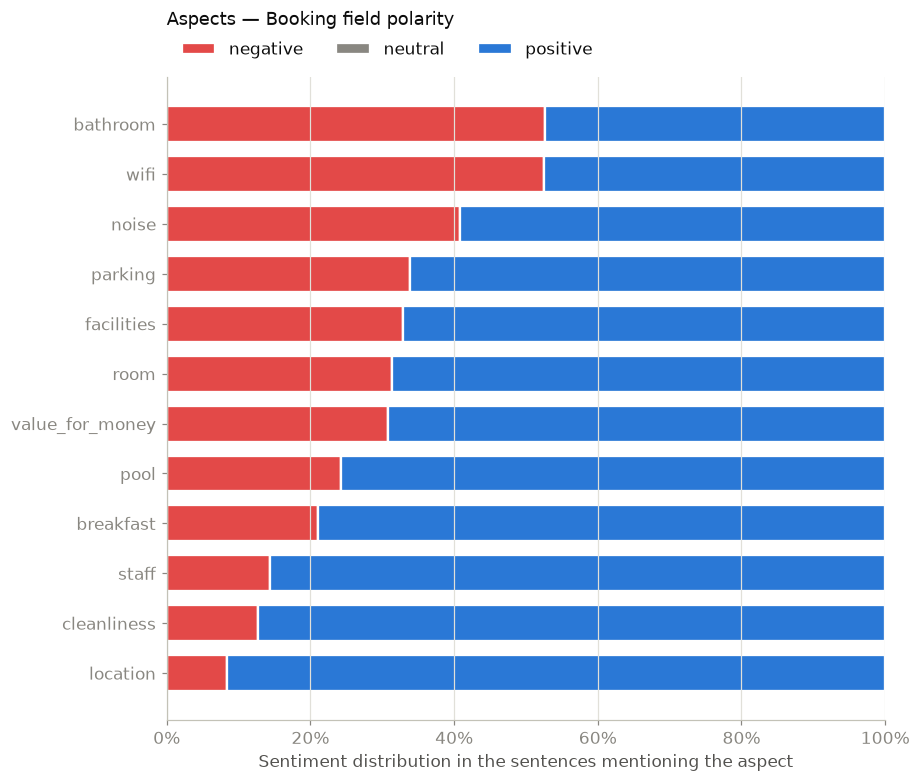

,mentions,mention_share,negative,neutral,positive,neg_lift,pos_lift
aspect,,,,,,,
bathroom,47309,0.0516,0.4626,0.0487,0.4888,2.1928,0.6588
wifi,7336,0.0080,0.4402,0.0559,0.5040,2.0866,0.6793
noise,31760,0.0346,0.3221,0.0432,0.6348,1.5268,0.8556
facilities,63040,0.0687,0.2823,0.0400,0.6777,1.3382,0.9134
parking,16861,0.0184,0.2738,0.0594,0.6668,1.2978,0.8988
room,199485,0.2174,0.2612,0.0445,0.6943,1.2380,0.9359
pool,22553,0.0246,0.2289,0.0318,0.7393,1.0850,0.9964
value_for_money,46003,0.0501,0.2049,0.0523,0.7428,0.9711,1.0012
breakfast,105038,0.1145,0.1877,0.0470,0.7652,0.8899,1.0314


21:03:37 | INFO    | src.evaluation | Table saved: 04_aspects_by_bert_sentence.csv
21:03:38 | INFO    | src.evaluation | Figure saved: 04_aspects_by_bert_sentence.png


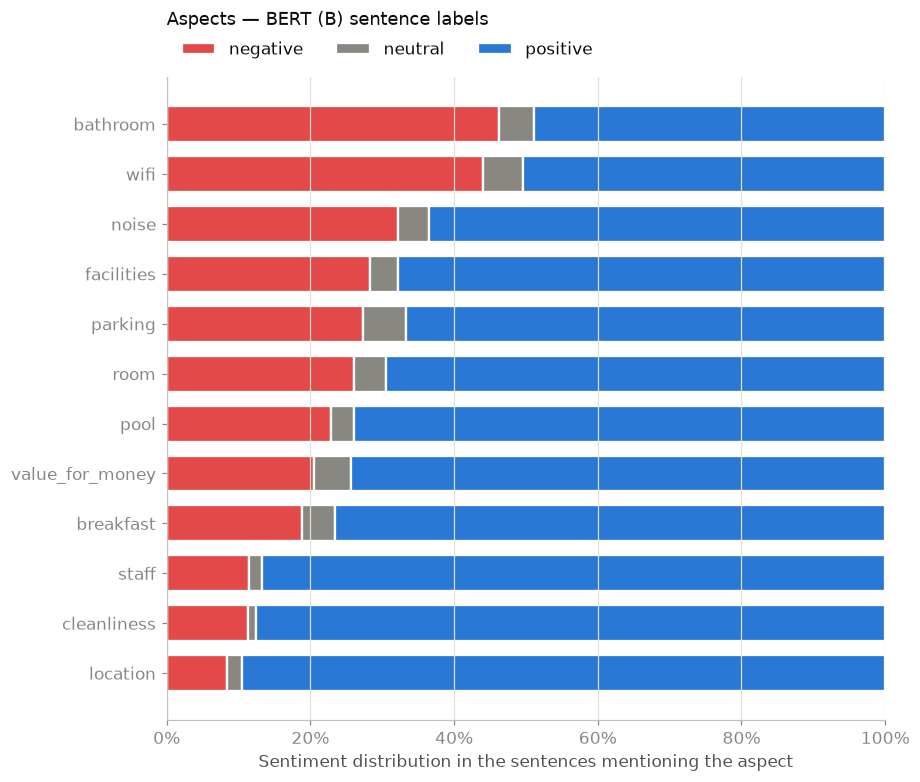

In [7]:
field_sent = asp.add_aspect_columns(asp.explode_by_polarity(data))
aspect_field = asp.aspect_sentiment_table(field_sent, label_col="field_polarity", min_count=50)
display(aspect_field); ev.save_table(aspect_field, "04_aspects_by_field_polarity")
asp.plot_aspect_sentiment(aspect_field, "Aspects — Booking field polarity", save_as="04_aspects_by_field_polarity")
plt.show()

if dl.frame_exists(PATHS.labels / "sentences_B"):
    sent_b = asp.add_aspect_columns(dl.read_frame(PATHS.labels / "sentences_B"))
    aspect_b = asp.aspect_sentiment_table(sent_b, label_col="B_label", min_count=50)
    display(aspect_b); ev.save_table(aspect_b, "04_aspects_by_bert_sentence")
    asp.plot_aspect_sentiment(aspect_b, "Aspects — BERT (B) sentence labels", save_as="04_aspects_by_bert_sentence")
    plt.show()

## 4. Klasszikus "tanítvány" modellek / Classical "student" models

HU: A mért pontosság itt a **BERT-címkékkel való egyezés** (tudásdesztilláció). A valódi pontosságot a gold mintán
mérjük (5. pont). `TRAIN_ON_UNANIMOUS=True`: csak az egybehangzó (legbiztosabb) címkéken tanít.
EN: The measured accuracy here is **agreement with the BERT labels** (knowledge distillation). True accuracy is measured
on the gold sample (section 5). `TRAIN_ON_UNANIMOUS=True`: trains only on the unanimous (most reliable) labels.

In [8]:
TRAIN_ON_UNANIMOUS = False
# HU: A gold minta véleményei NEM kerülhetnek a tanítóhalmazba, különben az 5. pont gold-összevetése
#     nem lenne független (a modell látta volna ezeket a szövegeket a (B)-címkével).
# EN: The gold-sample reviews must NOT be in the training data, otherwise the gold comparison in
#     section 5 would not be independent (the model would have seen these texts with the (B) label).
gold_ids = set(lv.load_gold().index) if (PATHS.annotation / "gold_sample_to_annotate.csv").exists() else set()
model_data = data[~data["review_id"].isin(gold_ids)]
print(f"Excluded gold reviews from model training: {len(data) - len(model_data)}")
train_df, val_df, test_df = pp.train_val_test_split(model_data, label_col=LABEL_COL)
if TRAIN_ON_UNANIMOUS and "unanimous" in train_df:
    train_df = train_df[train_df["unanimous"]]

display(ev.baseline_metrics(test_df[LABEL_COL]))

t0 = time.time()
summary, fitted = mc.train_and_evaluate_all(train_df, val_df, label_col=LABEL_COL)
print(f"Training time: {time.time() - t0:.1f} s")
display(summary[["accuracy", "f1_macro", "f1_weighted", "n_features"]].round(4))
ev.save_table(summary, "04_classical_validation")

21:03:39 | INFO    | src.label_validation | Gold sample read from: gold_sample_to_annotate.xlsx
21:03:39 | WARNING | src.label_validation | 1 rows without a valid gold_label are ignored.


Excluded gold reviews from model training: 399


21:03:41 | INFO    | src.preprocessing | Split — train: 121757 | val: 40586 | test: 40586


,accuracy,f1_macro,f1_weighted
baseline,,,
majority class ('positive'),0.7881,0.2938,0.6947
stratified random,0.6523,0.3378,0.6520
uniform random,0.3377,0.2617,0.4123


21:03:42 | INFO    | src.models_classical | Training: nb (121757 samples)
21:04:03 | INFO    | src.models_classical | Model saved: tfidf_nb_label_final.joblib
21:04:03 | INFO    | src.models_classical | Training: logreg (121757 samples)
21:04:35 | INFO    | src.models_classical | Model saved: tfidf_logreg_label_final.joblib
21:04:35 | INFO    | src.models_classical | Training: svm (121757 samples)
21:05:07 | INFO    | src.models_classical | Model saved: tfidf_svm_label_final.joblib


Training time: 85.3 s


,accuracy,f1_macro,f1_weighted,n_features
model,,,,
logreg,0.7850,0.6215,0.8038,50000
svm,0.8115,0.5904,0.8119,50000
nb,0.8202,0.4386,0.7797,50000


21:05:07 | INFO    | src.evaluation | Table saved: 04_classical_validation.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/04_classical_validation.csv')

Best on validation: logreg


,precision,recall,f1-score,support
negative,0.407,0.599,0.485,2319.000
neutral,0.405,0.578,0.476,6280.000
positive,0.948,0.836,0.889,31987.000
accuracy,0.783,0.783,0.783,0.783
macro avg,0.587,0.671,0.617,40586.000
weighted avg,0.833,0.783,0.802,40586.000


21:05:23 | INFO    | src.evaluation | Figure saved: 04_confusion_matrices_classical.png


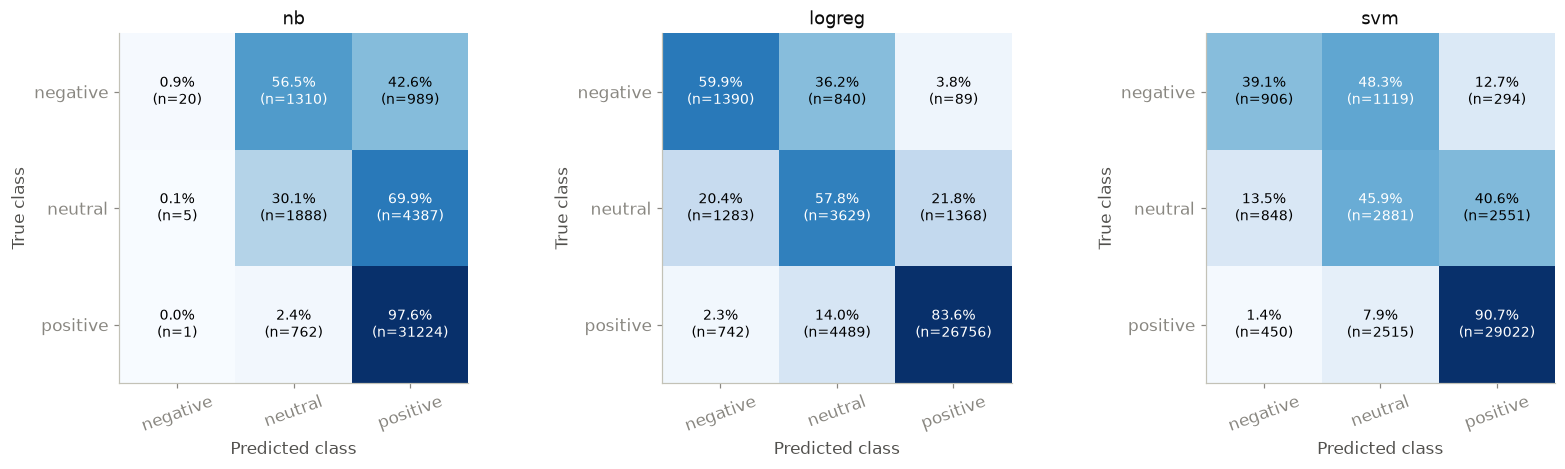

In [9]:
best_name = summary.index[0]
y_true = test_df[LABEL_COL].astype(str)
y_pred = fitted[best_name].predict(test_df["text_clean"])
print(f"Best on validation: {best_name}")
display(ev.per_class_report(y_true, y_pred).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, name in zip(axes, mc.MODEL_NAMES):
    ev.plot_confusion_matrix(y_true, fitted[name].predict(test_df["text_clean"]), title=name, ax=ax)
plt.tight_layout(); ev.save_figure("04_confusion_matrices_classical"); plt.show()

In [10]:
# HU: Ablációs vizsgálat mintán (8 változat). / EN: Ablation study on a sample (8 variants).
abl_train = train_df.sample(min(20_000, len(train_df)), random_state=CFG.random_seed)
ablation = mc.preprocessing_ablation(abl_train, val_df, label_col=LABEL_COL)
display(ablation[["accuracy", "f1_macro", "n_features"]].round(4))
ev.save_table(ablation, "04_preprocessing_ablation")

21:05:52 | INFO    | src.models_classical | raw text, unigram                    macro-F1 = 0.5896
21:06:06 | INFO    | src.models_classical | raw text, uni+bigram                 macro-F1 = 0.6079
21:06:10 | INFO    | src.models_classical | full cleaning, unigram               macro-F1 = 0.5799
21:06:18 | INFO    | src.models_classical | full cleaning, uni+bigram            macro-F1 = 0.6016
21:06:30 | INFO    | src.models_classical | full cleaning, uni+bi+trigram        macro-F1 = 0.6000
21:06:39 | INFO    | src.models_classical | full cleaning, sublinear_tf off      macro-F1 = 0.6017
21:06:46 | INFO    | src.models_classical | full cleaning, max_features=10k      macro-F1 = 0.5946
21:06:55 | INFO    | src.models_classical | cleaning, negation words dropped     macro-F1 = 0.5790


,accuracy,f1_macro,n_features
variant,,,
"raw text, uni+bigram",0.7901,0.6079,48519
"full cleaning, sublinear_tf off",0.7836,0.6017,34316
"full cleaning, uni+bigram",0.7838,0.6016,34316
"full cleaning, uni+bi+trigram",0.7852,0.6000,45706
"full cleaning, max_features=10k",0.7740,0.5946,10000
"raw text, unigram",0.7664,0.5896,7626
"full cleaning, unigram",0.7603,0.5799,6580
"cleaning, negation words dropped",0.7706,0.5790,33560


21:06:55 | INFO    | src.evaluation | Table saved: 04_preprocessing_ablation.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/04_preprocessing_ablation.csv')

21:06:55 | INFO    | src.evaluation | Table saved: 04_top_features_logreg.csv
21:06:57 | INFO    | src.evaluation | Figure saved: 04_top_features_logreg.png


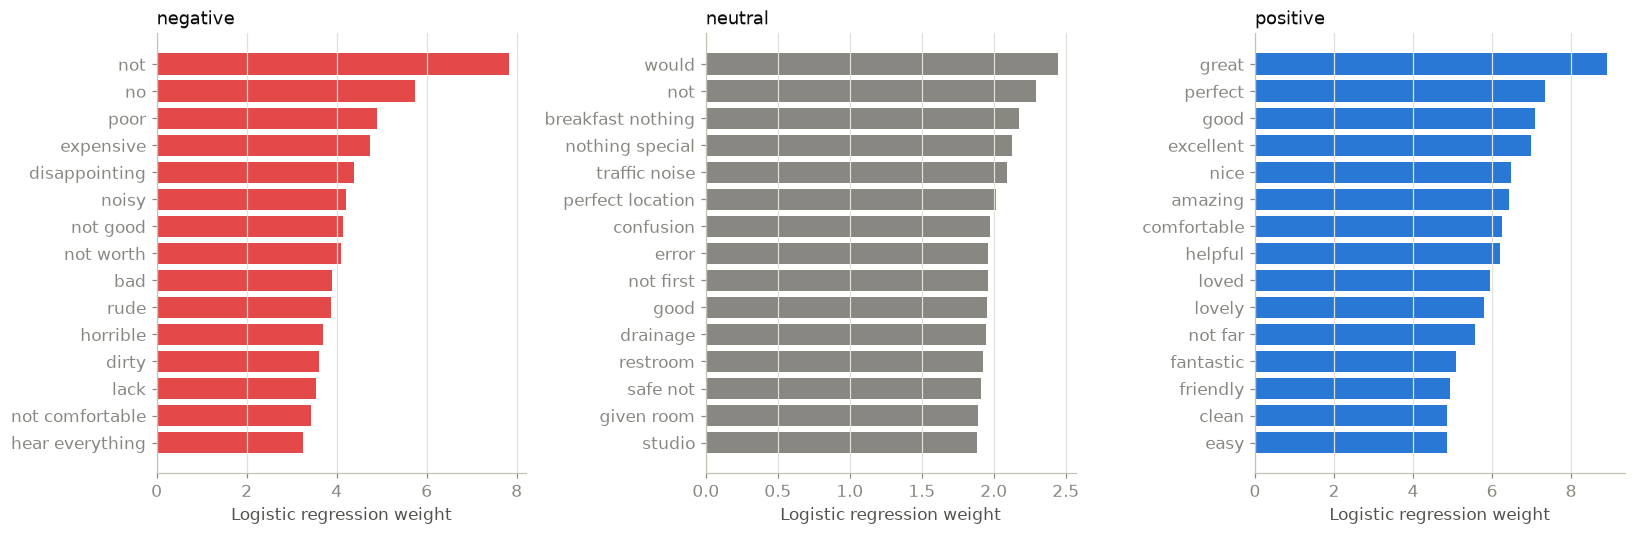

21:06:58 | INFO    | src.evaluation | Errors: 8811 / 40586 (21.7%)
21:06:58 | INFO    | src.evaluation | Table saved: 04_error_examples.csv


,error_type,true,predicted,score,text
0,negative -> neutral,negative,neutral,8.0,"Very clean, good location and rooms were okay. Rooms were not soundproof and you can hear the other guests in front ..."
1,negative -> neutral,negative,neutral,8.0,amazing. the leisure facilities were amazing and really good value for money at dinner only faults are that the show...
2,negative -> neutral,negative,neutral,8.0,"Clean, kind staff, and comfortable rooms. Parking can be challenging, cars got broken into, including ours during ou..."
3,negative -> neutral,negative,neutral,5.0,"Will never go back. The location was in the heart of Times Square, so close to nearby subways. The bathroom had a re..."
4,negative -> neutral,negative,neutral,7.0,"We arrived late night and checked in without any problem, close to Gubalowka and Krupówki, big comfortable sofas You..."
5,negative -> positive,negative,positive,8.0,"close to the city, free parking, delicious breakfast,friendly staff the mattress was a bit uncomfortable,"
6,negative -> positive,negative,positive,6.0,value for money yyy it is reasonably priced for its services and location & The staffs were very good super helpful ...
7,negative -> positive,negative,positive,7.0,"Having a small kitchen. This place has lots of fly; The facilty.prepared fly swatter which helped. During our stay, ..."
8,negative -> positive,negative,positive,8.0,Close to the bus station a good place if you are moving but not the best part of town
9,negative -> positive,negative,positive,9.0,The view the service was great. My only concern was that it was quite far from everything. So it’s great as a getawa...


In [11]:
top = mc.top_features_per_class(fitted["logreg"], top_n=15)
ev.save_table(top, "04_top_features_logreg")
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, label in zip(axes, CFG.labels):
    sub = top[top["sentiment"] == label].sort_values("weight")
    ax.barh(sub["feature"], sub["weight"], color=SENTIMENT_COLORS[label])
    ax.set_title(label, loc="left"); ax.set_xlabel("Logistic regression weight")
    ax.grid(axis="y", visible=False)
plt.tight_layout(); ev.save_figure("04_top_features_logreg"); plt.show()

errors = ev.error_analysis(test_df, y_pred, label_col=LABEL_COL, n_examples=5)
ev.save_table(errors, "04_error_examples")
errors.head(10)

## 5. Összevetés a gold mintán / Comparison on the gold sample

In [12]:
gold_file = PATHS.annotation / "gold_sample_to_annotate.csv"
if gold_file.exists() and len(lv.load_gold()):
    gold = lv.load_gold()
    gold_data = data.set_index("review_id").loc[lambda d: d.index.isin(gold.index)].copy()
    gold_data[f"tfidf_{best_name}"] = fitted[best_name].predict(gold_data["text_clean"])
    sources = {"BERT final": "label_final", f"TF-IDF {best_name}": f"tfidf_{best_name}"}
    comparison = lv.evaluate_on_gold(gold, gold_data, sources)
    display(comparison); ev.save_table(comparison, "04_gold_bert_vs_tfidf")

    # HU: PÁROS SZIGNIFIKANCIA-PRÓBA: ugyanazon 399 véleményen kis különbség véletlen is lehet.
    #     McNemar-próba + bootstrap 95%-os intervallum a különbségre (TF-IDF − BERT).
    # EN: PAIRED SIGNIFICANCE TEST: on the same 399 reviews a small difference may be chance.
    #     McNemar test + bootstrap 95% interval for the difference (TF-IDF − BERT).
    paired = lv.paired_gold_test(gold, gold_data["label_final"], gold_data[f"tfidf_{best_name}"],
                                 names=("BERT final", f"TF-IDF {best_name}"))
    display(paired); ev.save_table(paired, "04_gold_bert_vs_tfidf_paired")
    print("Only BERT right: {only_a_right} | only TF-IDF right: {only_b_right} | "
          "McNemar p = {mcnemar_p:.3f}".format(**paired.attrs))
else:
    print("No annotated gold sample yet (see notebook 03, section 5).")

21:06:58 | INFO    | src.label_validation | Gold sample read from: gold_sample_to_annotate.xlsx
21:06:58 | WARNING | src.label_validation | 1 rows without a valid gold_label are ignored.
21:06:58 | INFO    | src.label_validation | Gold sample read from: gold_sample_to_annotate.xlsx
21:06:58 | WARNING | src.label_validation | 1 rows without a valid gold_label are ignored.
21:06:58 | INFO    | src.label_validation | Gold reviews matched with labels: 399


,n,accuracy,f1_macro,cohen_kappa
source,,,,
TF-IDF logreg,399,0.8120,0.6515,0.5676
BERT final,399,0.8045,0.6405,0.5046


21:06:58 | INFO    | src.evaluation | Table saved: 04_gold_bert_vs_tfidf.csv
21:07:34 | INFO    | src.label_validation | Paired gold test: only BERT final right 33 | only TF-IDF logreg right 36 | McNemar p = 0.810


,BERT final,TF-IDF logreg,diff (TF-IDF logreg − BERT final),ci_low,ci_high,significant
metric,,,,,,
accuracy,0.8045,0.8120,0.0075,-0.0326,0.0501,False
f1_macro,0.6405,0.6515,0.0110,-0.0676,0.0929,False
cohen_kappa,0.5046,0.5676,0.0629,-0.0326,0.1555,False


21:07:34 | INFO    | src.evaluation | Table saved: 04_gold_bert_vs_tfidf_paired.csv


Only BERT right: 33 | only TF-IDF right: 36 | McNemar p = 0.810
